# Quantum Machine Learning with Quantum Kernels

*Q Hackathon pre-training · QML module*

**Who this is for.** You know a little Python and the basics of quantum mechanics (states, inner products, measurement). You do **not** need to know machine learning or quantum computing; we build both up from scratch.

**How to use it.** Run the cells from top to bottom (in Google Colab: *Runtime → Run all*). Every cell has already been run once, so you can read the outputs before running anything. Wherever you see **Try it**, change a number and re-run the cell.

**What you will learn**

| Part | Topic | Level |
|---|---|---|
| 1 | Machine learning in 15 minutes: classification, feature maps, the **kernel trick**, support vector machines | basic |
| 2 | Putting data into qubits: **quantum feature maps** | basic |
| 3 | The **quantum kernel**, and how a quantum computer actually measures it (with shot noise) | basic → medium |
| 4 | A quantum SVM on IBM's *ad hoc* dataset, where the quantum kernel beats the classical one | medium |
| — | *End of the lecture. The rest is self-study.* | |
| 5 | Kernel bandwidth and **exponential concentration** (why more qubits is not automatically better) | medium |
| 6 | The other QML approach: the **variational quantum classifier (VQC)** | medium |
| 7 | Running on a real IBM quantum computer | medium |


**Where this comes from.** The quantum-kernel material follows the approach of Havlíček *et al.*, *Nature* **567**, 209 (2019) (IBM), and the quantum-kernel labs of IBM's Qiskit Global Summer School on Quantum Machine Learning and the Qiskit Machine Learning tutorials, simplified for beginners. The variational classifier in Part 6 is the method used in the QC4MC 2025 summer-school QML notebook.

Everything quantum is done with **[Qiskit](https://www.ibm.com/quantum/qiskit)** (IBM's open-source quantum SDK) and **Qiskit Machine Learning**; the classical machine learning is **scikit-learn**.

In [1]:
# ---- Setup: installs anything missing (needed in Google Colab, harmless elsewhere) ----
import importlib.util, subprocess, sys
needed = {"qiskit": "qiskit", "qiskit_machine_learning": "qiskit-machine-learning",
          "pylatexenc": "pylatexenc", "sklearn": "scikit-learn", "pandas": "pandas"}
missing = [pip_name for mod, pip_name in needed.items() if importlib.util.find_spec(mod) is None]
IN_COLAB = "google.colab" in sys.modules
if missing and IN_COLAB:
    print("Installing:", *missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
elif missing:
    # On your own computer we do NOT install into your current environment: Qiskit needs NumPy 2,
    # which can break older packages (pandas, tensorflow, numba, ...) that were built for NumPy 1.
    raise SystemExit(
        "Missing packages: " + ", ".join(missing) + "\n\nPlease create a clean environment once, in a terminal:\n"
        "    python3 -m venv qml-env\n"
        "    source qml-env/bin/activate        (Windows: qml-env\\Scripts\\activate)\n"
        "    pip install -r requirements.txt\n"
        "    python -m ipykernel install --user --name qml-env --display-name \"QML (qiskit)\"\n"
        "then restart Jupyter and choose  Kernel -> Change kernel -> QML (qiskit).\n"
        "Or simply upload this notebook to Google Colab and use Runtime -> Run all.")

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from IPython.display import display

import qiskit, qiskit_machine_learning, sklearn
print(f"qiskit {qiskit.__version__} | qiskit-machine-learning {qiskit_machine_learning.__version__} | "
      f"scikit-learn {sklearn.__version__} | numpy {np.__version__}")

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

# One fixed colour per role, used everywhere in the notebook
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
CLASS_COLORS = [BLUE, ORANGE]                          # class 0, class 1
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f2f2f0", ORANGE])  # decision function
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#f7f7f5", "#9cc3ee", BLUE, "#123d73"])  # kernel values

SEED = 42
rng = np.random.default_rng(SEED)

def show(fig):
    # display a figure returned by Qiskit (circuit drawings, histograms) exactly once
    display(fig); plt.close(fig)

Installing: qiskit qiskit-machine-learning pylatexenc
qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.6.1 | numpy 2.1.3


---
# Part 1 · Machine learning in 15 minutes

### What is a classification problem?

* We have **data points** $\vec x$ (a list of numbers, the *features*) and each one carries a **label** $y$ (here: 0 or 1, e.g. *non-metal* / *metal*).
* We want a rule $f(\vec x)\to y$ that predicts the label of points we have **never seen**.
* We *learn* the rule from a **training set**, and we check it on a separate **test set**. Accuracy on the test set is the only honest score: a model that memorises its training data is useless.

Let's start with a toy dataset of two concentric rings.

training points: 140   test points: 60   features per point: 2


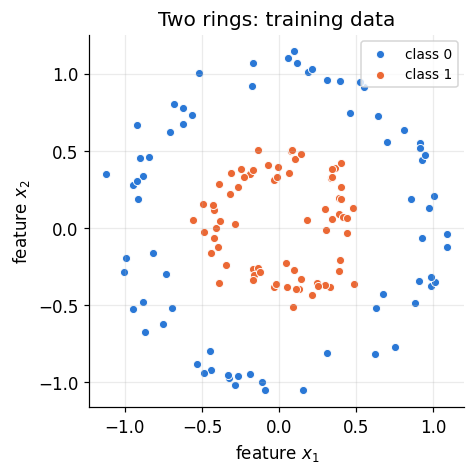

In [2]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

X_c, y_c = make_circles(n_samples=200, noise=0.08, factor=0.4, random_state=SEED)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_c, y_c, test_size=0.3, random_state=SEED, stratify=y_c)
print(f"training points: {len(Xc_train)}   test points: {len(Xc_test)}   features per point: {X_c.shape[1]}")

def scatter_classes(ax, X, y, marker="o", label_prefix="", **kw):
    for c in (0, 1):
        ax.scatter(*X[y == c].T, s=28, color=CLASS_COLORS[c], edgecolor="white", linewidth=0.6,
                   marker=marker, label=f"{label_prefix}class {c}", **kw)

fig, ax = plt.subplots(figsize=(4.6, 4.4))
scatter_classes(ax, Xc_train, yc_train)
ax.set_xlabel("feature $x_1$"); ax.set_ylabel("feature $x_2$"); ax.set_aspect("equal")
ax.set_title("Two rings: training data"); ax.legend(loc="upper right", fontsize=9)
plt.show()

## 1.1 A straight line is not enough

The simplest classifier draws a **straight line** (in more dimensions: a flat *hyperplane*) and says "class 0 on one side, class 1 on the other". Mathematically $f(\vec x)=\mathrm{sign}(\vec w\cdot\vec x+b)$, and *training* means choosing $\vec w,b$.

No straight line can separate a ring from the disk inside it. Let's confirm it: we train a **linear support vector machine** (more on SVMs below).

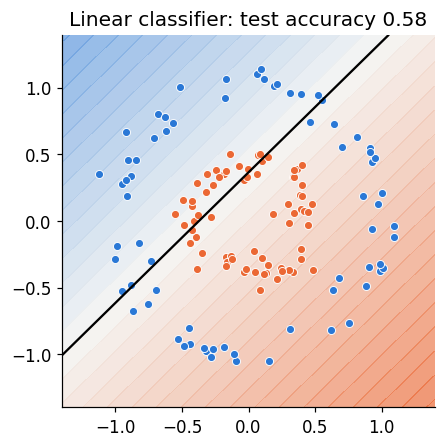

In [3]:
from sklearn.svm import SVC

def plot_decision(ax, model_fn, X, y, lims=(-1.4, 1.4), n=200, title="", X_test=None, y_test=None):
    # Colour the plane by the classifier's output: blue = predicts class 0, orange = predicts class 1
    g = np.linspace(*lims, n)
    GX, GY = np.meshgrid(g, g)
    Z = model_fn(np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)
    vmax = np.abs(Z).max()
    ax.contourf(GX, GY, Z, levels=30, cmap=DIVERGING, vmin=-vmax, vmax=vmax, alpha=0.7)
    ax.contour(GX, GY, Z, levels=[0], colors="k", linewidths=1.5)
    scatter_classes(ax, X, y)
    if X_test is not None:
        scatter_classes(ax, X_test, y_test, marker="s")
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False)

lin = SVC(kernel="linear").fit(Xc_train, yc_train)
fig, ax = plt.subplots(figsize=(4.6, 4.4))
plot_decision(ax, lin.decision_function, Xc_train, yc_train,
              title=f"Linear classifier: test accuracy {lin.score(Xc_test, yc_test):.2f}")
plt.show()

Only about 58%, barely better than flipping a coin.

## 1.2 The trick: a **feature map** into a bigger space

Add a third feature that we compute from the first two:

$$\vec x=(x_1,x_2)\;\longmapsto\;\phi(\vec x)=(x_1,\;x_2,\;x_1^2+x_2^2).$$

$\phi$ is called a **feature map**. The new coordinate is the squared distance from the centre, which is *small* for the inner disk and *large* for the outer ring. In the 3-dimensional feature space the two classes sit at different heights, and a flat plane separates them perfectly.

> **Key idea of the whole lecture.** Map the data into a bigger space where it becomes (almost) linearly separable, then draw a hyperplane there. In quantum machine learning the "bigger space" will be the **Hilbert space of qubits**, which is *exponentially* big.

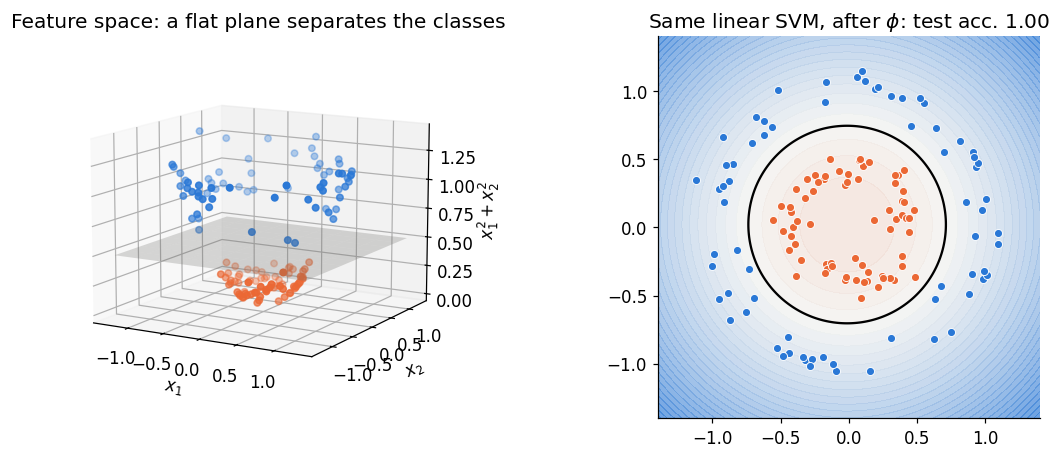

In [4]:
def phi(X):
    return np.c_[X, (X**2).sum(axis=1)]

fig = plt.figure(figsize=(11, 4.3))
ax = fig.add_subplot(1, 2, 1, projection="3d")
P = phi(Xc_train)
for c in (0, 1):
    ax.scatter(*P[yc_train == c].T, s=18, color=CLASS_COLORS[c], label=f"class {c}")
gx, gy = np.meshgrid(np.linspace(-1.3, 1.3, 10), np.linspace(-1.3, 1.3, 10))
ax.plot_surface(gx, gy, 0.5 + 0 * gx, color=GRAY, alpha=0.25)      # the separating plane x1^2+x2^2 = 0.5
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_1^2+x_2^2$")
ax.set_title("Feature space: a flat plane separates the classes"); ax.view_init(elev=12, azim=-60)

lin3 = SVC(kernel="linear").fit(phi(Xc_train), yc_train)
ax2 = fig.add_subplot(1, 2, 2)
plot_decision(ax2, lambda Z: lin3.decision_function(phi(Z)), Xc_train, yc_train,
              title=f"Same linear SVM, after $\\phi$: test acc. {lin3.score(phi(Xc_test), yc_test):.2f}")
plt.tight_layout(); plt.show()

A plane in feature space becomes a **circle** when we look back at the original plane. That is all a feature map does.

## 1.3 The kernel trick: we never need $\phi$ itself, only *similarities*

The **support vector machine (SVM)** finds the separating hyperplane with the widest possible margin. A beautiful fact from its mathematics: training and prediction use the data **only through inner products** $\phi(\vec x_i)\cdot\phi(\vec x_j)$. We call that inner product the **kernel**,

$$k(\vec x,\vec x') = \phi(\vec x)\cdot\phi(\vec x') \qquad(\text{a similarity score: large = similar}).$$

The trained SVM predicts

$$f(\vec x)=\mathrm{sign}\Big(\sum_{i\in\text{train}}\alpha_i\,y_i\,k(\vec x_i,\vec x)+b\Big),$$

where only a few training points (the **support vectors**, those closest to the boundary) get $\alpha_i\neq 0$.

So the recipe is:

1. Compute the **kernel matrix** (Gram matrix) $K_{ij}=k(\vec x_i,\vec x_j)$ for all pairs of training points.
2. Hand $K$ to a standard SVM solver. Training is a **convex** optimisation problem: unlike VQE, there are **no local minima**; the solver always finds the best answer.
3. To classify a new point, compute its kernel with the training points.

> **Why this matters for quantum computing.** Step 1 is the only place where the feature map enters. If a quantum computer can estimate $k(\vec x,\vec x')$ for a feature map that is hard to compute classically, we can plug it into a completely classical SVM. That is the **quantum kernel method** (also called **QSVM**).

A popular classical kernel is the Gaussian (RBF) kernel $k(\vec x,\vec x')=e^{-\gamma|\vec x-\vec x'|^2}$; its feature space is infinite-dimensional, yet $k$ costs one line of code. Let's look at its kernel matrix, with points sorted by class.

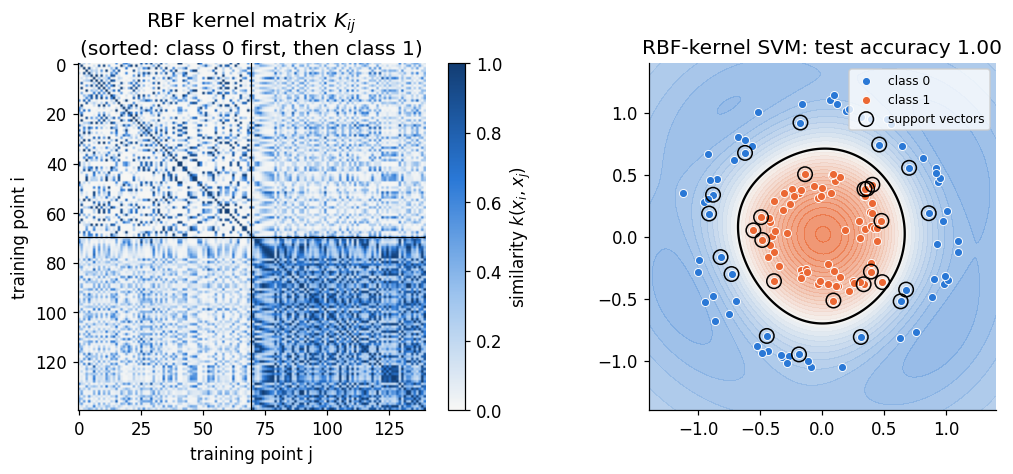

27 of 140 training points are support vectors.


In [5]:
from sklearn.metrics.pairwise import rbf_kernel

order = np.argsort(yc_train, kind="stable")
K_rbf = rbf_kernel(Xc_train[order], gamma=2.0)
rbf = SVC(kernel="rbf", gamma=2.0).fit(Xc_train, yc_train)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.4))
im = ax.imshow(K_rbf, cmap=SEQUENTIAL, vmin=0, vmax=1)
n0 = (yc_train == 0).sum()
ax.axhline(n0 - 0.5, color="k", lw=0.8); ax.axvline(n0 - 0.5, color="k", lw=0.8)
ax.set_title("RBF kernel matrix $K_{ij}$\n(sorted: class 0 first, then class 1)"); ax.grid(False)
ax.set_xlabel("training point j"); ax.set_ylabel("training point i")
plt.colorbar(im, ax=ax, fraction=0.046, label="similarity $k(x_i,x_j)$")

plot_decision(ax2, rbf.decision_function, Xc_train, yc_train,
              title=f"RBF-kernel SVM: test accuracy {rbf.score(Xc_test, yc_test):.2f}")
sv = rbf.support_vectors_
ax2.scatter(*sv.T, s=90, facecolor="none", edgecolor="k", linewidth=1, label="support vectors")
ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()
print(f"{len(sv)} of {len(Xc_train)} training points are support vectors.")

**Key takeaways of Part 1**
* Classification = learn a rule from labelled training data, judge it on unseen test data.
* A **feature map** $\phi$ moves data into a bigger space where a flat hyperplane can separate it.
* An SVM only needs the **kernel** $k(\vec x,\vec x')=\phi(\vec x)\cdot\phi(\vec x')$, a similarity score. Training is convex: no local minima.
* Next: build $\phi$ with **qubits**.

---
# Part 2 · Putting data into qubits: quantum feature maps

A **quantum feature map** is a parametrised circuit $U(\vec x)$ whose rotation angles are the data. Running it on $|0\dots0\rangle$ gives a quantum state

$$\vec x \;\longmapsto\; |\phi(\vec x)\rangle = U(\vec x)\,|0\dots 0\rangle .$$

The "feature vector" is now the **quantum state** itself, a vector with $2^n$ complex entries for $n$ qubits. The natural similarity of two states is their **fidelity** (overlap squared):

$$\boxed{\;k(\vec x,\vec x') = |\langle\phi(\vec x')|\phi(\vec x)\rangle|^2\;}$$

It is 1 for identical states and 0 for orthogonal ones. This is the **quantum kernel**.

## 2.1 One feature, one qubit

Encode a single number $x$ as a rotation angle: $|\phi(x)\rangle = R_y(x)|0\rangle=\cos\frac{x}{2}|0\rangle+\sin\frac{x}{2}|1\rangle$. On the Bloch sphere, $x$ is the polar angle. The overlap of two such states gives

$$k(x,x')=\cos^2\!\Big(\frac{x-x'}{2}\Big).$$

Let's build the circuit in Qiskit, compute the overlap from the simulated states, and check the formula.

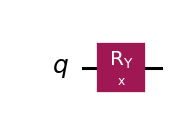

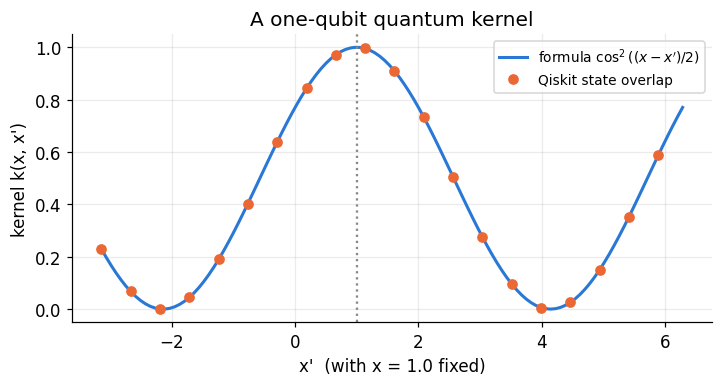

In [6]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter, ParameterVector
from qiskit.quantum_info import Statevector

x = Parameter("x")
fm1 = QuantumCircuit(1)
fm1.ry(x, 0)
show(fm1.draw("mpl"))

def kernel_from_states(circuit, x1, x2):
    # Quantum kernel |<phi(x2)|phi(x1)>|^2 computed from exact (simulated) state vectors
    s1 = Statevector(circuit.assign_parameters(np.atleast_1d(x1)))
    s2 = Statevector(circuit.assign_parameters(np.atleast_1d(x2)))
    return abs(s2.inner(s1))**2

x_ref = 1.0
xs = np.linspace(-np.pi, 2 * np.pi, 120)
k_qiskit = [kernel_from_states(fm1, x_ref, xv) for xv in xs]
k_formula = np.cos((xs - x_ref) / 2)**2

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(xs, k_formula, color=BLUE, lw=2, label=r"formula $\cos^2((x-x')/2)$")
ax.plot(xs[::6], k_qiskit[::6], "o", color=ORANGE, ms=6, label="Qiskit state overlap")
ax.axvline(x_ref, color=GRAY, ls=":")
ax.set_xlabel("x'  (with x = 1.0 fixed)"); ax.set_ylabel("kernel k(x, x')")
ax.set_title("A one-qubit quantum kernel"); ax.legend(fontsize=9)
plt.show()

Two things to notice:

* Points close in $x$ give overlap near 1 (similar); points that differ by $\pi$ give 0 (orthogonal). The kernel really is a similarity measure, just like the RBF one.
* The kernel is **periodic**: $x$ and $x+2\pi$ look identical to the qubit. That is why we always **rescale features** into a range like $[0,\pi]$ before encoding them. Forgetting this is the most common beginner mistake.

## 2.2 Several features: product maps vs. entangling maps

With $n$ features we use $n$ qubits. If each qubit gets its own rotation and nothing else, the state is a product state and the kernel is just a product of one-qubit kernels:

$$k(\vec x,\vec x')=\prod_{i=1}^{n}\cos^2\!\Big(\frac{x_i-x'_i}{2}\Big).$$

That is easy to compute on a laptop, so a quantum computer brings nothing. To get something classically hard we need **entanglement**, i.e. gates that make the features *interact*.

## 2.3 IBM's ZZ feature map

The feature map used in IBM's quantum-kernel paper (Havlíček *et al.* 2019) is the **ZZ feature map**. One layer is

$$U(\vec x)=\exp\Big(i\sum_{i}\varphi_i(\vec x)\,Z_i+i\sum_{i<j}\varphi_{ij}(\vec x)\,Z_iZ_j\Big)\,H^{\otimes n},
\qquad \varphi_i=x_i,\quad \varphi_{ij}=(\pi-x_i)(\pi-x_j),$$

and the layer is repeated `reps` times. In gates:

* **H** on every qubit (create superpositions),
* **P(2x$_i$)** phase rotation on qubit $i$ (encode each feature),
* **CX – P(2$\varphi_{ij}$) – CX** on each pair (encode *products* of features and entangle the qubits).

Qiskit has it built in as `zz_feature_map`. Let's draw the 2-qubit version with 2 repetitions.

Parameters (one per feature): [ParameterVectorElement(x[0]), ParameterVectorElement(x[1])]


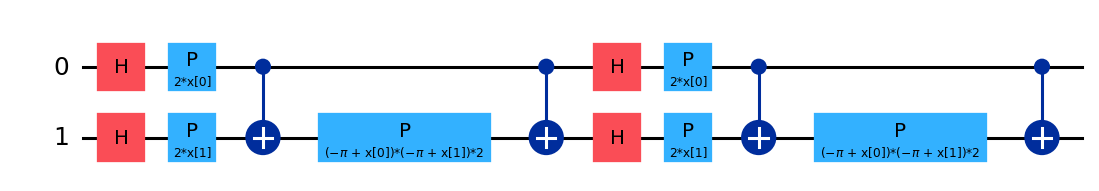

gates: {'p': 6, 'h': 4, 'cx': 4},  circuit depth: 10


In [7]:
from qiskit.circuit.library import zz_feature_map, z_feature_map

zz2 = zz_feature_map(feature_dimension=2, reps=2)
print("Parameters (one per feature):", list(zz2.parameters))
show(zz2.draw("mpl", fold=-1))
print(f"gates: {dict(zz2.count_ops())},  circuit depth: {zz2.depth()}")

**Key takeaways of Part 2**
* A quantum feature map is a circuit whose angles are the data. The feature vector is the quantum state $|\phi(\vec x)\rangle$.
* The **quantum kernel** is the state fidelity $|\langle\phi(\vec x')|\phi(\vec x)\rangle|^2$.
* Rescale your features (e.g. to $[0,\pi]$): rotations are periodic.
* Without entangling gates the kernel is classically easy. The ZZ map adds entanglement.

---
# Part 3 · The quantum kernel and how a quantum computer measures it

## 3.1 What a quantum computer can actually do

So far we computed overlaps from the simulated wavefunction. A real quantum computer can't hand us a wavefunction: it can only **run a circuit and measure**. The trick is the **compute–uncompute** circuit:

$$U^\dagger(\vec x')\,U(\vec x)\,|0\dots0\rangle .$$

The probability of measuring all zeros is

$$P(0\dots0)=|\langle 0\dots0|\,U^\dagger(\vec x')U(\vec x)\,|0\dots0\rangle|^2=|\langle\phi(\vec x')|\phi(\vec x)\rangle|^2 = k(\vec x,\vec x').$$

So **the kernel entry is just the fraction of shots that come out as 00…0.** If $\vec x=\vec x'$ the second half undoes the first and we always get 00…0, i.e. $k=1$.

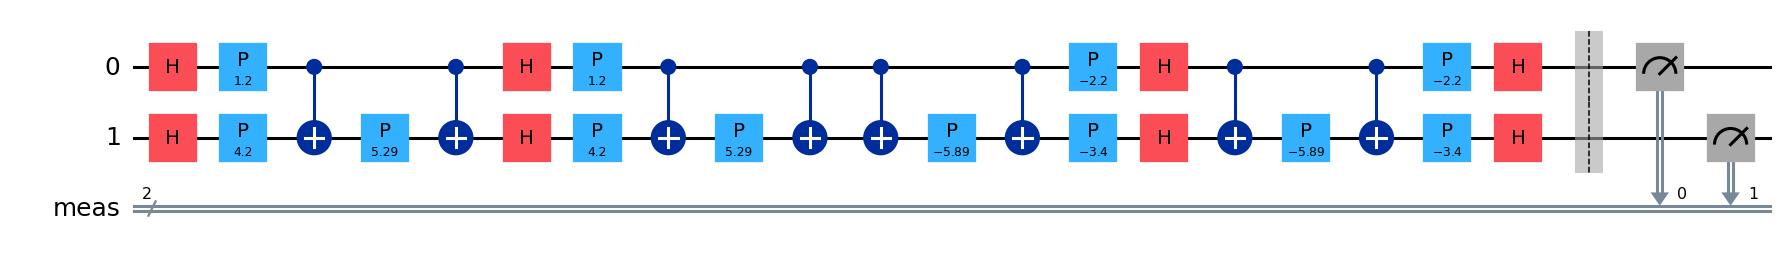

exact kernel from state vectors: k(x_a, x_b) = 0.5284


In [8]:
x_a = np.array([0.6, 2.1])
x_b = np.array([1.1, 1.7])

qc_kernel = zz2.assign_parameters(x_a).compose(zz2.assign_parameters(x_b).inverse())
qc_kernel.measure_all()
show(qc_kernel.draw("mpl", fold=-1))

k_exact = kernel_from_states(zz2, x_a, x_b)
print(f"exact kernel from state vectors: k(x_a, x_b) = {k_exact:.4f}")

Now "run it on a quantum computer". We use Qiskit's **Sampler** primitive, which returns measurement counts, just like hardware. (`StatevectorSampler` is a perfect, noise-free simulator that still draws a finite number of random shots.)

counts: {'10': 109, '00': 1059, '11': 473, '01': 359}
kernel estimate = P(00) = 1059/2000 = 0.5295   (exact 0.5284)


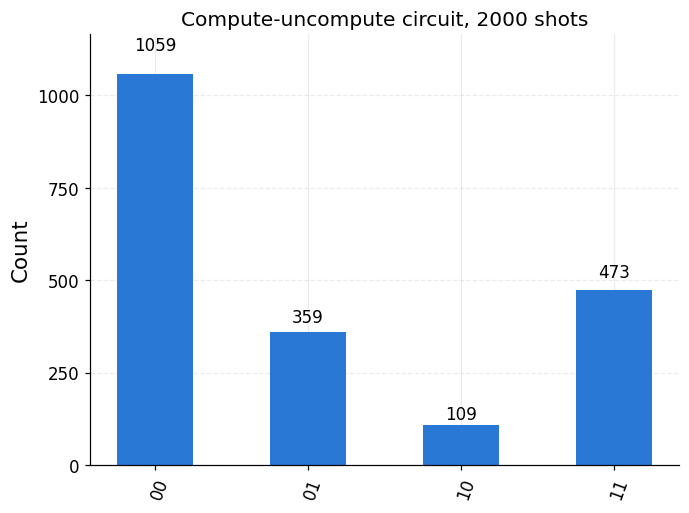

In [9]:
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

sampler = StatevectorSampler(seed=SEED)
shots = 2000
counts = sampler.run([qc_kernel], shots=shots).result()[0].data.meas.get_counts()
k_shots = counts.get("00", 0) / shots
print(f"counts: {counts}")
print(f"kernel estimate = P(00) = {counts.get('00', 0)}/{shots} = {k_shots:.4f}   (exact {k_exact:.4f})")
show(plot_histogram(counts, title=f"Compute-uncompute circuit, {shots} shots", color=BLUE))

### Shot noise

Each kernel entry is a probability estimated from a finite number of shots, so it carries statistical noise of size $\sqrt{k(1-k)/\text{shots}}$ (binomial statistics). Let's repeat the estimate 300 times for several shot budgets. The spread shrinks like $1/\sqrt{\text{shots}}$: **4× more shots for 2× less noise**, the same measurement bottleneck you met in VQE.

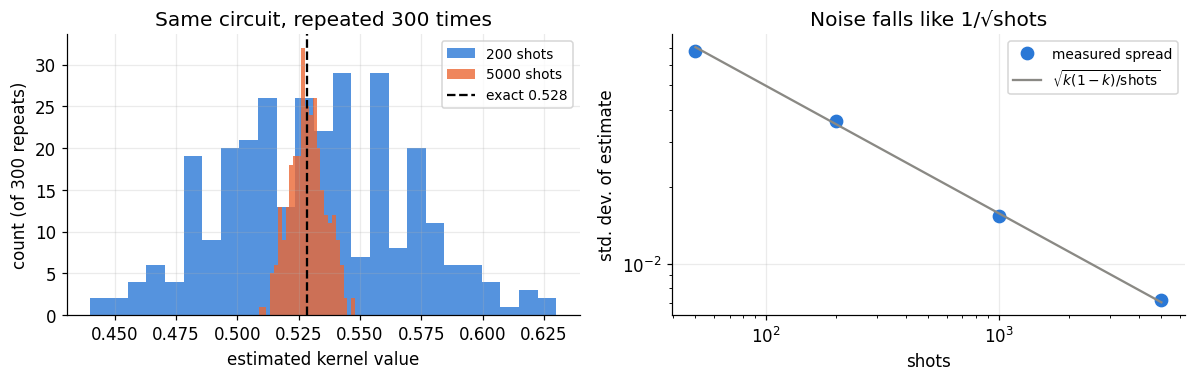

In [10]:
shot_list = [50, 200, 1000, 5000]
estimates = {}
for s in shot_list:
    est = []
    for _ in range(300):    # a fresh random seed each time = an independent experiment
        c = StatevectorSampler(seed=int(rng.integers(1_000_000))).run([qc_kernel], shots=s).result()[0]
        est.append(c.data.meas.get_counts().get("00", 0) / s)
    estimates[s] = np.array(est)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax.hist(estimates[200], bins=25, color=BLUE, alpha=0.8, label="200 shots")
ax.hist(estimates[5000], bins=25, color=ORANGE, alpha=0.8, label="5000 shots")
ax.axvline(k_exact, color="k", ls="--", label=f"exact {k_exact:.3f}")
ax.set_xlabel("estimated kernel value"); ax.set_ylabel("count (of 300 repeats)")
ax.set_title("Same circuit, repeated 300 times"); ax.legend(fontsize=9)

stds = [estimates[s].std() for s in shot_list]
theory = [np.sqrt(k_exact * (1 - k_exact) / s) for s in shot_list]
ax2.loglog(shot_list, stds, "o", color=BLUE, ms=8, label="measured spread")
ax2.loglog(shot_list, theory, "-", color=GRAY, label=r"$\sqrt{k(1-k)/\mathrm{shots}}$")
ax2.set_xlabel("shots"); ax2.set_ylabel("std. dev. of estimate"); ax2.set_title("Noise falls like 1/√shots")
ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 3.2 The whole kernel matrix with Qiskit Machine Learning

Doing this pair by pair is tedious. Qiskit Machine Learning has two classes for it:

| class | what it does | use it for |
|---|---|---|
| `FidelityQuantumKernel` | builds the compute–uncompute circuits and runs them on a **Sampler** (simulator *or* real hardware), with shots | the realistic setting / hardware |
| `FidelityStatevectorKernel` | computes exact overlaps from state vectors | fast, noise-free experiments on a laptop |

Both have the same method: `kernel.evaluate(x_vec, y_vec)` returns the matrix $K_{ij}=k(\vec x_i,\vec y_j)$. Let's check they agree on a few random points.

In [11]:
from qiskit_machine_learning.kernels import FidelityQuantumKernel, FidelityStatevectorKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute

X_demo = rng.uniform(0, np.pi, size=(5, 2))

qk_exact = FidelityStatevectorKernel(feature_map=zz2)
qk_shots = FidelityQuantumKernel(feature_map=zz2,
                                 fidelity=ComputeUncompute(sampler=StatevectorSampler(default_shots=4000, seed=SEED)))

np.set_printoptions(precision=3, suppress=True)
print("exact (state vectors):\n", qk_exact.evaluate(X_demo))
print("\nestimated from 4000 shots per entry (like hardware):\n", qk_shots.evaluate(X_demo))

exact (state vectors):
 [[1.    0.664 0.69  0.007 0.454]
 [0.664 1.    0.881 0.094 0.461]
 [0.69  0.881 1.    0.012 0.463]
 [0.007 0.094 0.012 1.    0.068]
 [0.454 0.461 0.463 0.068 1.   ]]

estimated from 4000 shots per entry (like hardware):
 [[1.    0.668 0.691 0.007 0.458]
 [0.668 1.    0.88  0.092 0.464]
 [0.691 0.88  1.    0.011 0.467]
 [0.007 0.092 0.011 1.    0.068]
 [0.458 0.464 0.466 0.068 1.   ]]


### How many circuits does this cost?

The matrix is symmetric with ones on the diagonal, so $N$ training points need $N(N-1)/2$ circuits, and every test point needs one circuit **per training point**:

| training points $N$ | circuits for training | circuits to classify 100 new points |
|---|---|---|
| 40 | 780 | 4 000 |
| 200 | 19 900 | 20 000 |
| 1 000 | 499 500 | 100 000 |

The cost grows like $N^2$. That's why quantum-kernel experiments use **small datasets** (tens to a few hundred points) and why picking good training points matters.

**Key takeaways of Part 3**
* On hardware, a kernel entry = the probability of measuring $0\dots0$ after the **compute–uncompute** circuit.
* Every entry carries **shot noise** $\propto 1/\sqrt{\text{shots}}$.
* `FidelityQuantumKernel` (shots, hardware-ready) and `FidelityStatevectorKernel` (exact, fast) build the whole matrix.
* Cost grows like $N^2$ in the number of training points.

---
# Part 4 · A quantum SVM on IBM's *ad hoc* dataset

## 4.1 The dataset

To show that a quantum kernel *can* help, Havlíček *et al.* built a dataset whose labels are defined **through the ZZ feature map itself**: a point gets label +1 or −1 depending on the expectation value of a fixed observable in the state $|\phi(\vec x)\rangle$, and points too close to the boundary are removed (a "gap"). Qiskit ships it as `ad_hoc_data`. Features are angles in $[0,2\pi]$.

Below, the pale background is 1000 extra points drawn from the same rule (to show the pattern); the bold dots are our 40 training points and the squares our 20 test points. The pattern is a complicated checkerboard, hard for standard classical kernels.

train: (40, 2), test: (20, 2), labels: [0 1]
plus 1000 extra points from the same rule, used only to draw the pattern and as a large check set


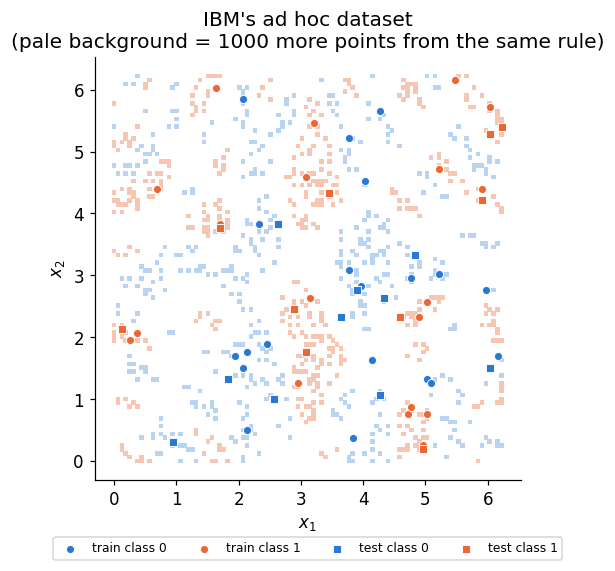

In [12]:
from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit_machine_learning.utils import algorithm_globals

# The random seed fixes the hidden "labelling rule" (a random observable), so both calls use the same rule.
algorithm_globals.random_seed = 12345
X_big, y_big, _, _ = ad_hoc_data(training_size=500, test_size=0, n=2, gap=0.3, one_hot=False)   # 1000 extra points
algorithm_globals.random_seed = 12345
X_train, y_train, X_test, y_test = ad_hoc_data(training_size=20, test_size=10, n=2, gap=0.3, one_hot=False)
print(f"train: {X_train.shape}, test: {X_test.shape}, labels: {np.unique(y_train)}")
print(f"plus {len(X_big)} extra points from the same rule, used only to draw the pattern and as a large check set")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*X_big.T, s=9, c=np.array(["#b9d3f2", "#f6c6b2"])[y_big], marker="s", linewidths=0)
scatter_classes(ax, X_train, y_train, label_prefix="train ")
scatter_classes(ax, X_test, y_test, marker="s", label_prefix="test ")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.grid(False)
ax.set_title("IBM's ad hoc dataset\n(pale background = 1000 more points from the same rule)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8)
plt.show()

## 4.2 Quantum vs. classical kernel matrices

Compute the ZZ-feature-map kernel on the training set and compare it with the RBF kernel. Sorted by class, a good kernel should look **block-diagonal**: high similarity *within* a class, low *between* classes.

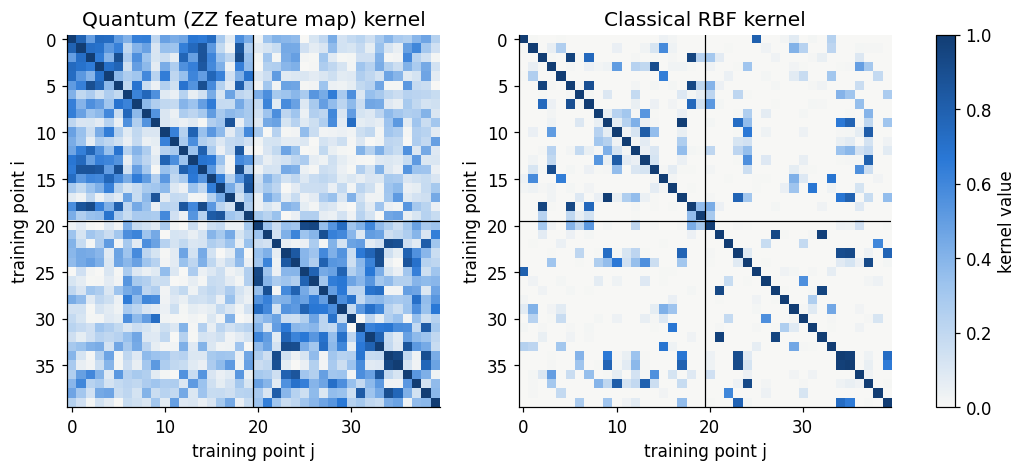

In [13]:
fmap = zz_feature_map(feature_dimension=2, reps=2)
qkernel = FidelityStatevectorKernel(feature_map=fmap)

K_train_q = qkernel.evaluate(X_train)              # 40 x 40, training vs training
K_test_q = qkernel.evaluate(X_test, X_train)       # 20 x 40, test vs training

order = np.argsort(y_train, kind="stable")
n0 = (y_train == 0).sum()
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, K, name in [(axes[0], K_train_q, "Quantum (ZZ feature map) kernel"),
                    (axes[1], rbf_kernel(X_train, gamma=1.0), "Classical RBF kernel")]:
    im = ax.imshow(K[np.ix_(order, order)], cmap=SEQUENTIAL, vmin=0, vmax=1)
    ax.axhline(n0 - 0.5, color="k", lw=0.8); ax.axvline(n0 - 0.5, color="k", lw=0.8)
    ax.set_title(name); ax.grid(False); ax.set_xlabel("training point j"); ax.set_ylabel("training point i")
plt.colorbar(im, ax=axes, fraction=0.025, label="kernel value")
plt.show()

## 4.3 Train the quantum SVM

Two equivalent ways:

1. **By hand:** give the precomputed kernel matrix to scikit-learn's `SVC(kernel="precomputed")`. This makes it crystal clear that the SVM itself is classical.
2. **`QSVC`** from Qiskit Machine Learning: an `SVC` that calls the quantum kernel for you.

For a fair comparison we give the classical RBF-SVM every advantage: its two hyperparameters ($C$, $\gamma$) are tuned by 5-fold cross-validation.

In [14]:
from qiskit_machine_learning.algorithms import QSVC
from sklearn.model_selection import GridSearchCV

# 1) by hand: classical SVM + quantum kernel matrix
svm_q = SVC(kernel="precomputed").fit(K_train_q, y_train)
acc_q = svm_q.score(K_test_q, y_test)

# 2) the same with QSVC
qsvc = QSVC(quantum_kernel=qkernel).fit(X_train, y_train)
acc_qsvc = qsvc.score(X_test, y_test)

# classical baseline, tuned
grid = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10, "scale"]}, cv=5)
grid.fit(X_train, y_train)
acc_rbf = grid.score(X_test, y_test)

results_adhoc = pd.DataFrame({
    "model": ["SVC + quantum kernel (precomputed)", "QSVC (Qiskit ML)", f"classical RBF SVM, tuned {grid.best_params_}"],
    "test accuracy": [acc_q, acc_qsvc, acc_rbf]})
results_adhoc["accuracy on the 1000 extra points"] = [
    svm_q.score(qkernel.evaluate(X_big, X_train), y_big), qsvc.score(X_big, y_big), grid.score(X_big, y_big)]
display(results_adhoc.style.format("{:.2f}", subset=["test accuracy", "accuracy on the 1000 extra points"]).hide(axis="index"))
print(f"support vectors used by the quantum SVM: {len(svm_q.support_)} of {len(y_train)}")

model,test accuracy,accuracy on the 1000 extra points
SVC + quantum kernel (precomputed),1.00,1.00
QSVC (Qiskit ML),1.00,1.00
"classical RBF SVM, tuned {'C': 10, 'gamma': 10}",0.90,0.69


support vectors used by the quantum SVM: 20 of 40


## 4.4 What did the quantum SVM learn?

We evaluate the trained quantum SVM on a grid of points covering the whole square and colour each by the SVM's output. Compare with the true regions in the plot of 4.1.

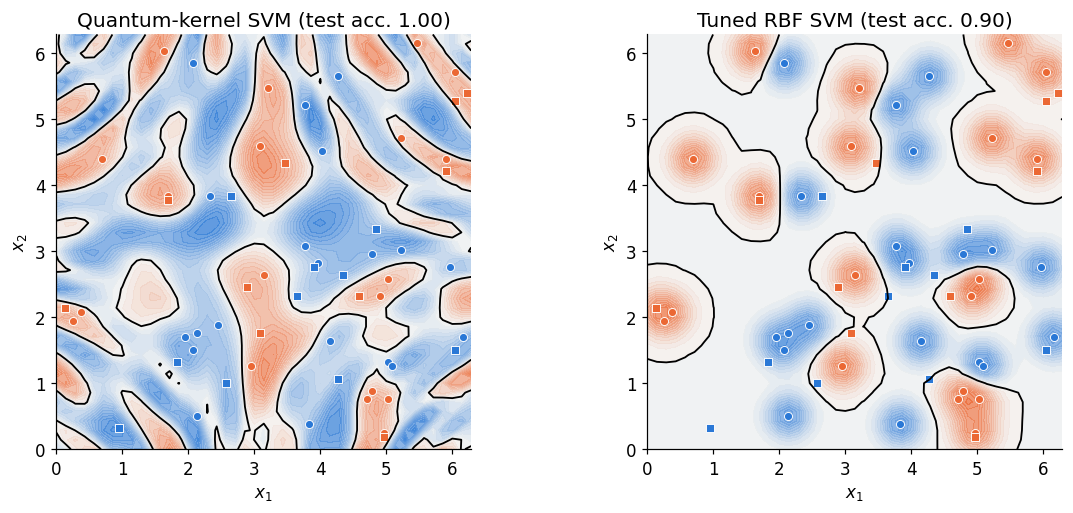

In [15]:
def decision_map_precomputed(svm, kernel, X_tr, lims, n=45):
    g = np.linspace(*lims, n)
    GX, GY = np.meshgrid(g, g)
    grid_pts = np.c_[GX.ravel(), GY.ravel()]
    Z = svm.decision_function(kernel.evaluate(grid_pts, X_tr)).reshape(GX.shape)
    return GX, GY, Z

GX, GY, Zq = decision_map_precomputed(svm_q, qkernel, X_train, (0, 2 * np.pi))
best_rbf = grid.best_estimator_
Zc = best_rbf.decision_function(np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, Z, title in [(axes[0], Zq, f"Quantum-kernel SVM (test acc. {acc_q:.2f})"),
                     (axes[1], Zc, f"Tuned RBF SVM (test acc. {acc_rbf:.2f})")]:
    v = np.abs(Z).max()
    ax.contourf(GX, GY, Z, levels=30, cmap=DIVERGING, vmin=-v, vmax=v, alpha=0.75)
    ax.contour(GX, GY, Z, levels=[0], colors="k", linewidths=1.2)
    scatter_classes(ax, X_train, y_train); scatter_classes(ax, X_test, y_test, marker="s")
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
plt.tight_layout(); plt.show()

Compare both maps with the pale background pattern in 4.1. The quantum SVM produces long, curved stripes, the same kind of shapes as the true pattern, because it uses the very feature space that generated the labels. The RBF SVM can only draw smooth blobs around the training points it has seen; between them it is guessing. The score on the 1000 extra points (table above) is the more reliable comparison: 20 test points are too few to tell models apart.

> **Be honest about this result.** The ad hoc dataset was *designed* so that the ZZ feature map is the perfect feature map for it. It shows that quantum kernels **can** capture structure that is hard for classical kernels. It does **not** show that quantum kernels beat classical methods on everyday data; for real-world data this is an open research question. In the hackathon challenge you will test a real materials dataset yourself.

**Key takeaways of Part 4**
* QSVM = quantum kernel matrix + ordinary classical SVM.
* When the data has the "right" structure, the quantum kernel wins clearly.
* The right feature map matters more than anything else.

---
### End of the lecture

The parts below are for **self-study and exploration**. The warm-up exercises and the **hackathon challenge** are in the companion notebook **`QML_2_Hackathon_Challenges.ipynb`**.

---
# Part 5 · (Self-study) Kernel bandwidth and exponential concentration

Quantum feature maps live in a $2^n$-dimensional space. That sounds like a great thing, but there's a catch: in a huge space, **two random states are almost orthogonal**. If the feature map spreads the data all over Hilbert space, every off-diagonal kernel entry becomes tiny,

$$K\approx \mathbb{1}\qquad (\text{every point is "dissimilar" to every other}).$$

Then the SVM can only memorise the training set and **cannot generalise**. Worse, telling apart numbers that are exponentially close to 0 needs exponentially many shots. This is called **exponential concentration** of quantum kernels (Thanasilp *et al.*, *Nat. Commun.* 2024). It's the kernel-method cousin of the "barren plateaus" of variational circuits.

### The bandwidth knob

For real data we add one hyperparameter. We use the ZZ circuit with the products of features as the two-qubit angles ($\varphi_{ij}=x_ix_j$), and multiply every feature by a **scale factor** $\lambda$ before encoding:

$$k_\lambda(\vec x,\vec x') = |\langle\phi(\lambda\vec x')|\phi(\lambda\vec x)\rangle|^2 .$$

$\lambda$ plays the role of $\gamma$ in the RBF kernel: **small** $\lambda$ = small rotations = all states look alike (a smooth, "wide" kernel); **large** $\lambda$ = big rotations = every point looks different from every other (a "spiky" kernel that just memorises). In practice $\lambda$ is chosen by **cross-validation**, which you will do in the hackathon challenge.

Let's measure concentration: random data with $n$ features on $n$ qubits, and the average off-diagonal kernel value, for three bandwidths.

In [16]:
def product_map(x):          # phi_i = x_i,  phi_ij = x_i * x_j   (scales cleanly with lambda)
    return x[0] if len(x) == 1 else x[0] * x[1]

def zz_kernel(n_features, reps=2):
    # ZZ feature-map kernel whose bandwidth is set by multiplying the data by lambda
    return FidelityStatevectorKernel(feature_map=zz_feature_map(n_features, reps=reps, data_map_func=product_map))

done in 8.0 s


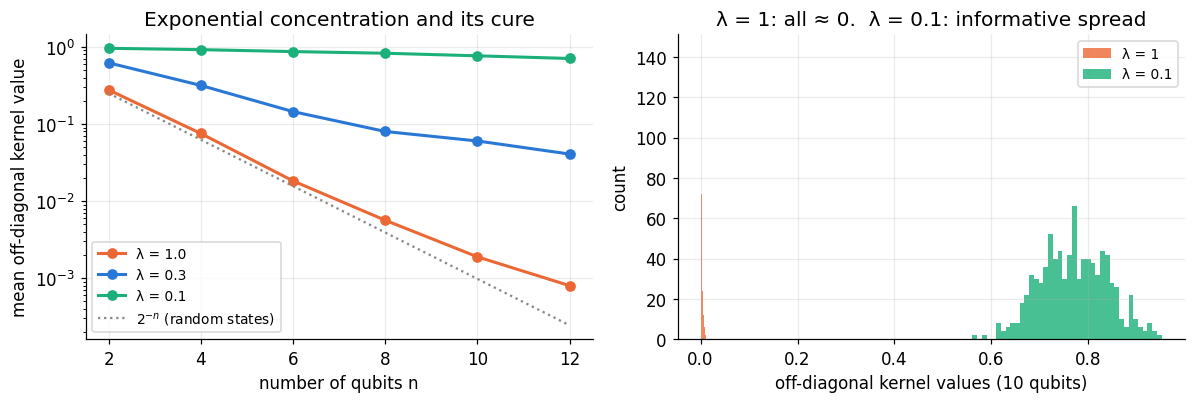

In [17]:
import time
n_points = 30
qubit_list = [2, 4, 6, 8, 10, 12]
conc = {lam: [] for lam in [1.0, 0.3, 0.1]}
t0 = time.time()
for n in qubit_list:
    Xr = rng.uniform(0, np.pi, size=(n_points, n))
    kern = zz_kernel(n, reps=2)
    for lam in conc:
        K = kern.evaluate(lam * Xr)
        conc[lam].append(K[~np.eye(n_points, dtype=bool)].mean())
print(f"done in {time.time() - t0:.1f} s")

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for lam, col in zip(conc, [ORANGE, BLUE, GREEN]):
    ax.semilogy(qubit_list, conc[lam], "o-", color=col, lw=2, label=f"λ = {lam}")
ax.semilogy(qubit_list, [2.0**-n for n in qubit_list], ":", color=GRAY, label="$2^{-n}$ (random states)")
ax.set_xlabel("number of qubits n"); ax.set_ylabel("mean off-diagonal kernel value")
ax.set_title("Exponential concentration and its cure"); ax.legend(fontsize=9)

Xr = rng.uniform(0, np.pi, size=(n_points, 10))
K10_full = zz_kernel(10).evaluate(Xr)
K10_small = zz_kernel(10).evaluate(0.1 * Xr)
ax2.hist(K10_full[~np.eye(n_points, dtype=bool)], bins=40, color=ORANGE, alpha=0.8, label="λ = 1")
ax2.hist(K10_small[~np.eye(n_points, dtype=bool)], bins=40, color=GREEN, alpha=0.8, label="λ = 0.1")
ax2.set_xlabel("off-diagonal kernel values (10 qubits)"); ax2.set_ylabel("count")
ax2.set_title("λ = 1: all ≈ 0.  λ = 0.1: informative spread"); ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

* With $\lambda=1$ the kernel values fall **exponentially** with the number of qubits, roughly like random states.
* Shrinking the rotations ($\lambda$ small) keeps the states in a smaller region of Hilbert space and the kernel stays informative (Shaydulin & Wild, *Phys. Rev. A* 2022; Canatar *et al.* 2022).
* But $\lambda\to0$ makes the kernel nearly constant and, eventually, classically simulable. The useful regime is in between, and **cross-validation finds it** (you will do exactly this in the hackathon challenge).

> **Practical rule for the hackathon:** whenever you use more than ~4 qubits, scan the bandwidth $\lambda$, and look at a histogram of your kernel values. If they are all ≈ 0, your model will not generalise.

---
# Part 6 · (Self-study) The other QML approach: the variational quantum classifier

Quantum kernels use the quantum computer only to **measure similarities**. The other big family, the **variational quantum classifier (VQC)**, trains the circuit itself, exactly like VQE:

1. **Feature map** $U(\vec x)$: encode the data (the same ZZ map).
2. **Ansatz** $W(\vec\theta)$: a trainable circuit with parameters $\vec\theta$ (here `real_amplitudes`: $R_y$ rotations + CNOTs).
3. **Measure**: the parity of the measured bitstring is read as the predicted class, with probabilities $p_\theta(y|\vec x)$.
4. **Classical optimiser** (COBYLA) tunes $\vec\theta$ to minimise the **cross-entropy loss** $-\sum_i\log p_\theta(y_i|\vec x_i)$.

$$|0\dots0\rangle \xrightarrow{\;U(\vec x)\;} \xrightarrow{\;W(\vec\theta)\;} \text{measure} \;\to\; \text{loss}(\vec\theta)\;\to\;\text{optimiser updates }\vec\theta$$

This is the method of the QC4MC 2025 QML notebook. Let's train it on the ad hoc data.

trainable parameters: 8


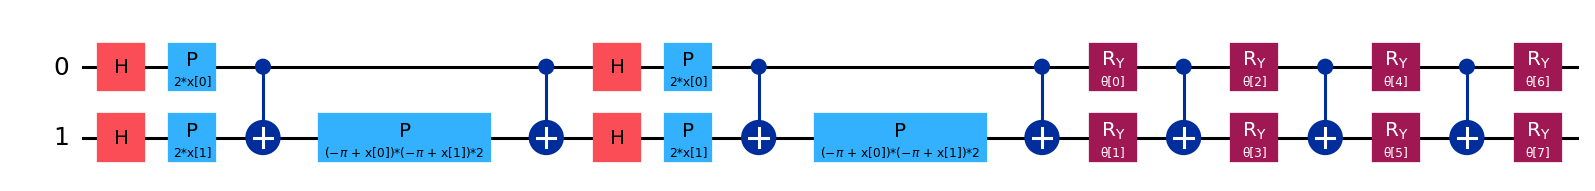

In [18]:
from qiskit.circuit.library import real_amplitudes
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA

ansatz = real_amplitudes(num_qubits=2, reps=3)
print(f"trainable parameters: {ansatz.num_parameters}")
show(fmap.compose(ansatz).draw("mpl", fold=-1))

training took 20 s and 83 loss evaluations


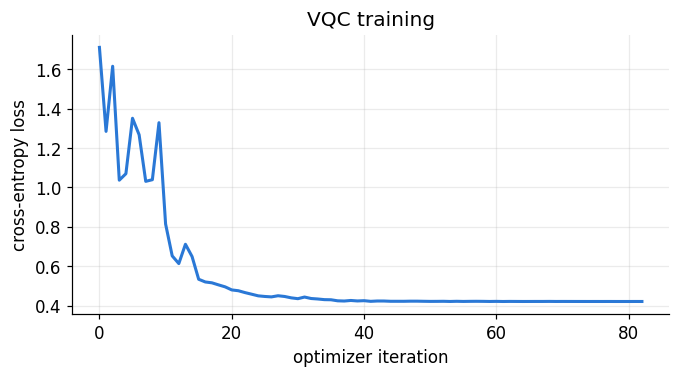

model,test accuracy
"VQC (ZZ map + RealAmplitudes, COBYLA)",1.00
quantum-kernel SVM (Part 4),1.00
tuned RBF SVM (Part 4),0.90


In [19]:
loss_history = []
algorithm_globals.random_seed = 12345
vqc = VQC(feature_map=fmap, ansatz=ansatz, optimizer=COBYLA(maxiter=150),
          sampler=StatevectorSampler(seed=SEED),        # 1024 shots per circuit by default
          callback=lambda weights, loss: loss_history.append(loss))
t0 = time.time()
vqc.fit(X_train, y_train)
print(f"training took {time.time() - t0:.0f} s and {len(loss_history)} loss evaluations")

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(loss_history, color=BLUE, lw=2)
ax.set_xlabel("optimizer iteration"); ax.set_ylabel("cross-entropy loss"); ax.set_title("VQC training")
plt.show()

acc_vqc_train, acc_vqc_test = vqc.score(X_train, y_train), vqc.score(X_test, y_test)
display(pd.DataFrame({"model": ["VQC (ZZ map + RealAmplitudes, COBYLA)", "quantum-kernel SVM (Part 4)", "tuned RBF SVM (Part 4)"],
                      "test accuracy": [acc_vqc_test, acc_q, acc_rbf]})
        .style.format({"test accuracy": "{:.2f}"}).hide(axis="index"))

### Kernel method or VQC?

| | quantum kernel (QSVM) | variational classifier (VQC) |
|---|---|---|
| what is trained | a classical SVM | the quantum circuit parameters $\vec\theta$ |
| optimisation | **convex**: global optimum guaranteed | non-convex: local minima, barren plateaus, depends on the start |
| quantum cost | $\sim N^2$ kernel circuits, once | (iterations) × $N$ circuits |
| scales to large $N$? | poorly ($N^2$) | better |
| main pitfall | kernel concentration (Part 5) | trainability (barren plateaus) |

Both start from the same ingredient: **a good feature map**.

---
# Part 7 · (Self-study) Running on a real IBM quantum computer

Everything above used simulators. To use real hardware you need a free IBM Quantum account ([quantum.cloud.ibm.com](https://quantum.cloud.ibm.com)) and an API key. Only **three things change**:

1. Pick a real **backend**.
2. **Transpile** the feature map for that device: rewrite it in the device's native gates and map it onto its physical qubits.
3. Replace `StatevectorSampler` with the runtime **`SamplerV2`**.

The cell below is not run here (it needs your credentials and queue time). Copy it into a code cell to try it. Keep the dataset **tiny** (e.g. 10 training points = 45 kernel circuits), because each circuit costs QPU time.

```python
# pip install qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit.transpiler import generate_preset_pass_manager

# one-time: QiskitRuntimeService.save_account(token="YOUR_API_KEY", instance="YOUR_CRN", overwrite=True)
service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False)
print("running on", backend.name)

pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
fmap_isa = pm.run(zz_feature_map(2, reps=2))           # hardware-ready circuit

sampler_hw = SamplerV2(mode=backend)
sampler_hw.options.default_shots = 1000
qk_hw = FidelityQuantumKernel(feature_map=fmap_isa,
                              fidelity=ComputeUncompute(sampler=sampler_hw, pass_manager=pm))

K_hw = qk_hw.evaluate(X_train[:10])                    # 45 circuits sent to the QPU
svm_hw = SVC(kernel="precomputed").fit(K_hw, y_train[:10])
```

On hardware the kernel entries come out **smaller than they should** (noise pulls the probability of $00\dots0$ down) and the diagonal is no longer exactly 1. Shallow feature maps (`reps=1`) and error mitigation help.

---
# Wrap-up

| Idea | Where we saw it |
|---|---|
| Classification, train/test split, feature maps, the kernel trick, SVMs (convex: no local minima) | Part 1 |
| Quantum feature maps; quantum kernel = state fidelity; rescale features; entanglement via the ZZ map | Part 2 |
| Measuring a kernel entry with the compute–uncompute circuit; shot noise ∝ 1/√shots; $N^2$ cost | Part 3 |
| QSVM on IBM's ad hoc dataset: quantum kernel clearly beats a tuned RBF kernel (on data built for it) | Part 4 |
| Kernel bandwidth, exponential concentration and how to avoid it | Part 5 |
| Variational quantum classifier (VQC) vs. kernel methods | Part 6 |
| Running on IBM hardware | Part 7 |
| Real materials data (is this element a metal?) | **your hackathon challenge** |

### References
* V. Havlíček *et al.*, "Supervised learning with quantum-enhanced feature spaces", *Nature* **567**, 209 (2019).
* M. Schuld & N. Killoran, "Quantum machine learning in feature Hilbert spaces", *PRL* **122**, 040504 (2019).
* S. Thanasilp *et al.*, "Exponential concentration in quantum kernel methods", *Nat. Commun.* **15**, 5200 (2024).
* R. Shaydulin & S. M. Wild, "Importance of kernel bandwidth in quantum machine learning", *PRA* **106**, 042407 (2022).
* Qiskit Machine Learning documentation and tutorials: <https://qiskit-community.github.io/qiskit-machine-learning/>
* QC4MC Summer School 2025, QML notebook: <https://github.com/qc4mc/qc4mcsummer2025/tree/main/QML>